# FBW2 tryptophans in AGO1 pockets: mutation candidates

**Question.** In the ColabFold models of AGO1 (O04379, chain A) × FBW2 (Q9ZPE4, chain B), do the FBW2 tryptophans
W225, W258, W275, W295 and W313 insert into **cavities of AGO1**? Which AGO1 residues line those cavities, and
which mutations (on AGO1 or on FBW2) are worth testing in the pull-down / degradation assay?

**Approach**
1. **Model confidence**: 5 AF2-multimer v3 samples (`results_ago1_autophagy_colabfold`), weighted by ipTM.
2. **Cavity detection with pyKVFinder** (Guerra *et al.*, *BMC Bioinformatics* 2021; parKVFinder, *SoftwareX* 2020)
   on **apo AGO1**: FBW2 is removed, so the space the Trp side chain occupied becomes cavity if AGO1 wraps around it.
   * *global map*: which AGO1 cavity each Trp sits in (any cavity ≥ 5,000 Å³ is the central nucleic-acid channel);
   * *Trp sub-pocket*: pyKVFinder ligand mode, with the Trp side chain as the "ligand" (cavity restricted to 5 Å
     around it). This gives volume, depth, hydropathy and lining residues.
3. **PLIP** contacts (pipeline output `plip_contacts.parquet`) for the interaction types made by each Trp.
4. **CDD sites** (`cdd_sites.parquet`) and domain boundaries: bonus when a pocket is a known functional site.
5. Score AGO1 residues across samples and propose **mutations**.

Environment: `envs/cavity_notebook.yaml` (kernel `nanopulldown-cavity-notebook`).

In [1]:
import os
os.environ.setdefault("KMP_WARNINGS", "0")      # pyKVFinder's libomp: silence "omp_set_nested deprecated"
import logging, tempfile, json
from pathlib import Path
import numpy as np, pandas as pd, gemmi, pyKVFinder, yaml
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", "overflow encountered in cast")  # pandas repr of NaN cols
logging.getLogger().setLevel(logging.ERROR)      # pyKVFinder logs one warning per atom with no tabulated radius
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

ROOT = Path("..") if Path("../Snakefile").exists() else Path(".")
RUN, PAIR = "ago1_autophagy_colabfold", "O04379__Q9ZPE4"
BAIT, PREY = "A", "B"                            # AGO1, FBW2
TRP = [225, 258, 275, 295, 313]                  # FBW2 tryptophans under test

STEP, PROBE_IN, PROBE_OUT = 0.6, 1.4, 8.0        # probe_out 8 Å: also catches shallow grooves (4 Å finds only deep ones)
LIGAND_CUTOFF = 5.0                              # Å around the Trp side chain = "Trp sub-pocket"
PLDDT_TRIM = 0.5                                 # drop AGO1 residues below this pLDDT (floppy N-term -> fake cavities)
CONTACT = 4.5                                    # Å heavy-atom contact to the indole ring
CHANNEL_MIN_VOL = 5000.0                         # Å3: a global cavity this big is the central RNA channel
INDOLE = ["CG", "CD1", "CD2", "NE1", "CE2", "CE3", "CZ2", "CZ3", "CH2"]
FORCE = False                                    # True = recompute pyKVFinder even if cached

PAIR_DIR = ROOT / f"results_{RUN}" / PAIR
ANNOT = ROOT / "data/annotation_ago1_autophagy"
OUT = ROOT / f"reports_{RUN}" / "fbw2_trp_pockets"; OUT.mkdir(parents=True, exist_ok=True)
print("pyKVFinder", pyKVFinder.__version__, "| gemmi", gemmi.__version__, "| out:", OUT.resolve())

pyKVFinder 0.9.7 | gemmi 0.7.5 | out: /Users/ereboul/projects/NanoPulldown/reports_ago1_autophagy_colabfold/fbw2_trp_pockets


## 1. Model confidence

In [2]:
fold = pd.read_parquet(PAIR_DIR / "raw/fold.parquet").sort_values("sample_index").reset_index(drop=True)
im = pd.read_parquet(PAIR_DIR / "interface_metrics.parquet")
fold = fold.merge(im[["sample_index", "ipsae", "pdockq", "lis"]], on="sample_index")

def token_maps(row):
    tc, ri = np.array(row.token_chain), np.array(row.residue_index)
    idx = {(c, int(r) + 1): i for i, (c, r) in enumerate(zip(tc, ri))}
    return idx, np.array(row.plddt), np.array(row.pae).reshape(len(tc), len(tc))

conf = []
for _, row in fold.iterrows():
    idx, pl, _ = token_maps(row)
    conf.append({"sample": row.sample_index, "iptm": row.iptm, "ptm": row.ptm, "ipsae": row.ipsae,
                 "pdockq": row.pdockq, **{f"pLDDT_W{w}": pl[idx[(PREY, w)]] for w in TRP}})
conf = pd.DataFrame(conf)
conf["weight"] = conf.iptm / conf.iptm.sum()     # sample weight used in the residue scores below
conf.round(2)

,sample,iptm,ptm,ipsae,pdockq,pLDDT_W225,pLDDT_W258,pLDDT_W275,pLDDT_W295,pLDDT_W313,weight
0,0,0.53,0.66,0.43,0.43,0.629883,0.469971,0.689941,0.270020,0.280029,0.35
1,1,0.24,0.64,0.01,0.45,0.640137,0.300049,0.370117,0.209961,0.239990,0.16
2,2,0.26,0.63,0.01,0.39,0.700195,0.239990,0.399902,0.239990,0.150024,0.17
3,3,0.22,0.64,0.01,0.24,0.629883,0.250000,0.290039,0.160034,0.160034,0.15
4,4,0.26,0.64,0.01,0.35,0.680176,0.209961,0.379883,0.199951,0.150024,0.17


Only **sample 0** has a confident interface (ipTM 0.53, ipSAE 0.43). Samples 1–4 have ipTM ≈ 0.25. Consensus
across all five samples still counts, because AF2 placing the same Trp in the same pocket in low-ipTM samples is
evidence too, but scores are ipTM-weighted. W295 and W313 have low pLDDT in every sample.

## 2. pyKVFinder on apo AGO1
For each sample: strip hydrogens, keep AGO1 residues with pLDDT ≥ 0.5, run a **global** detection and then one
**ligand-mode** detection per Trp. Results are cached in `OUT/kvfinder_*.parquet` (about 2 min for 5 samples).

In [3]:
def _write(chains, path):
    st = gemmi.Structure(); st.add_model(gemmi.Model("1"))
    for name, residues in chains.items():
        ch = gemmi.Chain(name)
        for r in residues: ch.add_residue(r)
        st[0].add_chain(ch)
    st.setup_entities(); st.write_pdb(str(path))


def run_sample(s, row, wd, export=False):
    idx, plddt, pae = token_maps(row)
    st = gemmi.read_structure(str(PAIR_DIR / f"minimized/sample_{s}.pdb.gz")); st.remove_hydrogens(); m = st[0]
    A, B = m[BAIT], m[PREY]
    rec = wd / f"ago1_s{s}.pdb"
    _write({BAIT: [r for r in A if plddt[idx[(BAIT, r.seqid.num)]] >= PLDDT_TRIM]}, rec)
    atomic = pyKVFinder.read_pdb(str(rec))
    vert = pyKVFinder.get_vertices(atomic, probe_out=PROBE_OUT, step=STEP)
    o = vert[0]; ax = np.array([(vert[i] - o) / np.linalg.norm(vert[i] - o) for i in (1, 2, 3)])

    def tags_at(grid, xyz, r=1.2):                       # cavity ids of the voxels within r Å of a point
        ijk = np.rint(((xyz - o) @ ax.T) / STEP).astype(int); k = int(np.ceil(r / STEP)); out = []
        for d in np.ndindex(2 * k + 1, 2 * k + 1, 2 * k + 1):
            q = ijk + np.array(d) - k
            if np.all(q >= 0) and np.all(q < grid.shape) and grid[tuple(q)] > 1: out.append(int(grid[tuple(q)]))
        return out

    _, cav = pyKVFinder.detect(atomic, vert, step=STEP, probe_in=PROBE_IN, probe_out=PROBE_OUT)
    _, gvol, _ = pyKVFinder.spatial(cav, step=STEP)
    ns = gemmi.NeighborSearch(m, st.cell, 6).populate()
    T, R = [], []
    for w in TRP:
        res = B[str(w)][0]
        ind = np.array([a.pos.tolist() for a in res if a.name in INDOLE])
        flat = [t for x in ind for t in tags_at(cav, x)]
        gname = pyKVFinder.grid._get_cavity_name(max(set(flat), key=flat.count) - 2) if flat else None
        gv = gvol[gname] if gname else np.nan
        # Trp sub-pocket (ligand mode)
        sc = res.clone()
        for name in ("N", "C", "O"): sc.remove_atom(name, "\0")
        lig = wd / f"trp{w}_s{s}.pdb"; _write({PREY: [sc]}, lig)
        n2, sub = pyKVFinder.detect(atomic, vert, step=STEP, probe_in=PROBE_IN, probe_out=PROBE_OUT,
                                    latomic=pyKVFinder.read_pdb(str(lig)), ligand_cutoff=LIGAND_CUTOFF)
        lining, vol, area, dmax, davg, hyd = set(), 0.0, 0.0, 0.0, 0.0, np.nan
        if n2 > 0:
            surf, v, a_ = pyKVFinder.spatial(sub, step=STEP)
            dep, maxd, avgd = pyKVFinder.depth(sub, step=STEP)
            _, hydro = pyKVFinder.hydropathy(surf, atomic, vert, step=STEP)
            cons = pyKVFinder.constitutional(sub, atomic, vert, step=STEP, probe_in=PROBE_IN)
            vol, area = sum(v.values()), sum(a_.values()); dmax = max(maxd.values())
            davg = sum(avgd[k] * v[k] for k in v) / vol; hyd = sum(hydro[k] * v[k] for k in v) / vol
            for k in cons: lining |= {int(r[0]) for r in cons[k]}
            if export:
                pyKVFinder.export(str(OUT / f"pocket_W{w}_sample{s}.pdb"), sub, surf, vert, step=STEP)
        occ = float(np.mean([len(tags_at(sub, x, 1.0)) > 0 for x in ind])) if n2 else 0.0
        contact = {}
        for a in res:
            if a.name not in INDOLE: continue
            for mk in ns.find_atoms(a.pos, "\0", radius=CONTACT):
                c = mk.to_cra(m)
                if c.chain.name == BAIT:
                    rn = c.residue.seqid.num; contact[rn] = min(contact.get(rn, 9e9), c.atom.pos.dist(a.pos))
        iw = idx[(PREY, w)]
        pae_ = lambda rn: 0.5 * (pae[idx[(BAIT, rn)], iw] + pae[iw, idx[(BAIT, rn)]])
        for rn in sorted(lining | set(contact)):
            R.append(dict(sample=s, trp=w, ago1_resnr=rn, ago1_resname=A[str(rn)][0].name,
                          lines_subpocket=rn in lining, indole_contact=rn in contact,
                          min_dist=contact.get(rn, np.nan), plddt=plddt[idx[(BAIT, rn)]], pae=pae_(rn)))
        T.append(dict(sample=s, trp=w, trp_plddt=plddt[iw], global_cavity=gname, global_vol=gv,
                      in_channel=bool(gname) and gv >= CHANNEL_MIN_VOL, sub_volume=vol, sub_area=area,
                      sub_depth_max=dmax, sub_depth_avg=davg, sub_hydropathy=hyd, indole_in_cavity=occ,
                      n_lining=len(lining), n_contacts=len(contact),
                      pae_contacts=np.mean([pae_(r) for r in contact]) if contact else np.nan))
    return pd.DataFrame(T), pd.DataFrame(R)


f_trp, f_res = OUT / "kvfinder_trp.parquet", OUT / "kvfinder_residues.parquet"
if FORCE or not (f_trp.exists() and f_res.exists()):
    wd = Path(tempfile.mkdtemp()); parts = [run_sample(int(r.sample_index), r, wd, export=True) for _, r in fold.iterrows()]
    pd.concat([p[0] for p in parts]).to_parquet(f_trp, index=False)
    pd.concat([p[1] for p in parts]).to_parquet(f_res, index=False)
trp = pd.read_parquet(f_trp).merge(conf[["sample", "iptm", "weight"]], on="sample")
res = pd.read_parquet(f_res).merge(conf[["sample", "iptm", "weight"]], on="sample")
trp.round(2)

,sample,trp,trp_plddt,global_cavity,global_vol,in_channel,sub_volume,sub_area,sub_depth_max,sub_depth_avg,sub_hydropathy,indole_in_cavity,n_lining,n_contacts,pae_contacts,iptm,weight
0,0,225,0.629883,NaN,NaN,False,0.00,0.00,0.00,0.00,NaN,0.00,0,1,25.59,0.53,0.35
1,0,258,0.469971,KAE,15388.70,True,464.83,117.08,3.06,0.94,-0.18,1.00,11,3,10.65,0.53,0.35
2,0,275,0.689941,KAE,15388.70,True,842.62,238.00,5.53,1.56,1.20,1.00,17,5,4.61,0.53,0.35
3,0,295,0.270020,NaN,NaN,False,8.64,8.04,0.60,0.04,0.73,0.00,5,5,18.33,0.53,0.35
4,0,313,0.280029,KAU,86.18,False,85.97,87.63,3.45,1.11,0.16,1.00,10,8,18.80,0.53,0.35
5,1,225,0.640137,NaN,NaN,False,9.07,8.52,0.60,0.04,0.40,0.00,6,2,27.20,0.24,0.16
6,1,258,0.300049,KAA,15507.72,True,390.53,89.95,2.24,0.63,-0.39,1.00,8,3,18.83,0.24,0.16
7,1,275,0.370117,KAA,15507.72,True,939.60,252.79,5.09,1.53,1.39,1.00,16,4,12.86,0.24,0.16
8,1,295,0.209961,KAA,15507.72,True,486.86,256.32,6.95,1.67,1.20,1.00,16,6,21.39,0.24,0.16
9,1,313,0.239990,NaN,NaN,False,0.00,0.00,0.00,0.00,NaN,0.00,0,2,26.09,0.24,0.16


### Per-Trp summary across the 5 samples

In [4]:
summary = trp.groupby("trp").agg(
    n_in_channel=("in_channel", "sum"),
    n_buried=("indole_in_cavity", lambda x: int((x >= 0.5).sum())),
    w_buried=("indole_in_cavity", lambda x: float((x * trp.loc[x.index, "weight"]).sum())),
    sub_volume=("sub_volume", "median"), depth_max=("sub_depth_max", "median"),
    hydropathy=("sub_hydropathy", "median"), n_contacts=("n_contacts", "median"),
    trp_plddt=("trp_plddt", "mean"), pae_contacts=("pae_contacts", "median"),
    sample0_pae=("pae_contacts", lambda x: float(x[trp.loc[x.index, "sample"] == 0].iloc[0])),
).sort_values("w_buried", ascending=False)
summary.round(2)

,n_in_channel,n_buried,w_buried,sub_volume,depth_max,hydropathy,n_contacts,trp_plddt,pae_contacts,sample0_pae
trp,,,,,,,,,,
275,5,5,1.00,842.62,5.26,1.25,4.0,0.43,12.02,4.61
258,4,4,0.83,390.53,3.06,0.17,3.0,0.29,21.00,10.65
313,0,1,0.35,0.00,0.00,0.16,0.0,0.20,22.45,18.80
295,1,1,0.16,31.10,0.85,0.52,3.0,0.22,21.04,18.33
225,0,0,0.04,0.00,0.00,-0.08,1.0,0.66,27.86,25.59


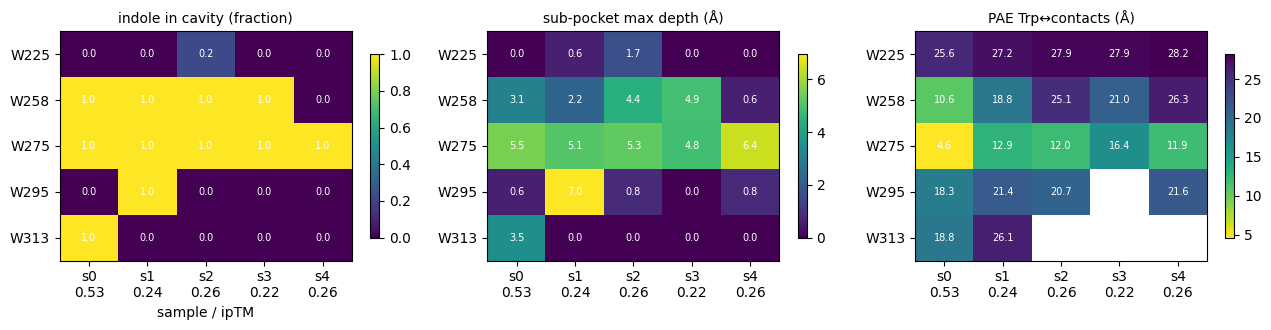

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, lab in zip(axes, ["indole_in_cavity", "sub_depth_max", "pae_contacts"],
                        ["indole in cavity (fraction)", "sub-pocket max depth (Å)", "PAE Trp↔contacts (Å)"]):
    piv = trp.pivot(index="trp", columns="sample", values=col)
    im_ = ax.imshow(piv.values, cmap="viridis_r" if col == "pae_contacts" else "viridis", aspect="auto")
    ax.set_yticks(range(len(piv)), [f"W{w}" for w in piv.index]); ax.set_xticks(range(5), [f"s{s}\n{conf.iptm[s]:.2f}" for s in piv.columns])
    ax.set_title(lab, fontsize=10); fig.colorbar(im_, ax=ax, shrink=0.8)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, "" if np.isnan(v) else f"{v:.1f}", ha="center", va="center", fontsize=7, color="w")
axes[0].set_xlabel("sample / ipTM"); fig.tight_layout(); fig.savefig(OUT / "trp_pocket_heatmaps.png", dpi=150)

**Reading.** **W275** sits in the large central cavity in **5/5** samples (the cavity bigger than 5,000 Å³, i.e.
the nucleic-acid channel between PAZ, MID and PIWI). Its indole is fully inside the cavity, the sub-pocket is deep
(max depth ≈ 5–6 Å, ≈ 700–1,000 Å³) and it has the best Trp↔AGO1 PAE (≈ 4.6 Å in the confident sample 0).
**W258** enters the same channel in 4/5 samples but less deeply and with weaker PAE. W225, W295 and W313 are
mostly solvent-exposed or only transiently packed, and W295 and W313 are themselves low-pLDDT.

## 3. Which AGO1 residues line the Trp sub-pockets? (+ PLIP, CDD, domains)

In [6]:
plip = pd.read_parquet(PAIR_DIR / "plip_contacts.parquet")
plip_trp = (plip[(plip.reschain_lig == PREY) & plip.resnr_lig.isin(TRP)]
            .groupby(["sample", "resnr_lig", "resnr"]).interaction_type
            .agg(lambda x: ",".join(sorted(set(x)))).rename("plip").reset_index()
            .rename(columns={"resnr_lig": "trp", "resnr": "ago1_resnr"}))
res = res.merge(plip_trp, on=["sample", "trp", "ago1_resnr"], how="left")

# CDD functional sites + domain boundaries for AGO1
cdd = pd.read_parquet(ANNOT / "cdd_sites.parquet")
cdd = cdd[(cdd.pair == PAIR) & (cdd.chain == BAIT) & cdd.site.notna()]
site_of = {}
for _, r in cdd.iterrows():
    for p in r.residues: site_of.setdefault(int(p), []).append(f"{r.cdd_name}: {r.site}")
doms = [d for d in yaml.safe_load(open(ANNOT / PAIR / "annotation.yaml"))["domains"][BAIT] if d["kind"] == "domain"]
domain_of = lambda n: next((d["name"].replace("Protein argonaute, ", "").replace("Argonaute ", "") for d in doms
                            if d["start"] <= n <= d["end"]), "-")
display(cdd[["cdd_name", "site", "residues"]])

,cdd_name,site,residues
91,PAZ_argonaute_like,nucleic acid-binding interface,"[435, 450, 461, 465, 483, 490, 492]"
93,Piwi_ago-like,active site,"[760, 762, 846, 986]"
94,Piwi_ago-like,5' RNA guide strand anchoring site,"[689, 693, 705, 706, 707, 708, 711, 719, 722, ..."


In [7]:
# AGO1 residue score: ipTM-weighted support over samples
#   1.0 x indole contact (≤ 4.5 Å) + 0.5 x lines the Trp sub-pocket + 0.5 x PLIP interaction with that Trp
res["support"] = res.weight * (1.0 * res.indole_contact + 0.5 * res.lines_subpocket + 0.5 * res.plip.notna())
cand = (res.groupby(["trp", "ago1_resnr", "ago1_resname"])
        .agg(score=("support", "sum"), n_samples=("sample", "nunique"),
             n_contact=("indole_contact", "sum"), n_lining=("lines_subpocket", "sum"),
             min_dist=("min_dist", "min"), pae=("pae", "mean"), plddt=("plddt", "mean"),
             plip=("plip", lambda x: ";".join(sorted({t for v in x.dropna() for t in v.split(",")}))))
        .reset_index())
cand["domain"] = cand.ago1_resnr.map(domain_of)
cand["cdd_site"] = cand.ago1_resnr.map(lambda n: " | ".join(site_of.get(n, [])))
cand = cand.sort_values(["trp", "score"], ascending=[True, False])
for w in [275, 258]:
    print(f"\n=== W{w} sub-pocket (top residues) ===")
    display(cand[cand.trp == w].head(18).round(2).reset_index(drop=True))


=== W275 sub-pocket (top residues) ===


,trp,ago1_resnr,ago1_resname,score,n_samples,n_contact,n_lining,min_dist,pae,plddt,plip,domain,cdd_site
0,275,886,LYS,1.91,5,5,5,2.83,10.93,0.81,hydrogen_bonds;hydrophobic_interactions;pi-cat...,Piwi domain,
1,275,978,ILE,1.70,5,4,5,3.65,11.93,0.90,hydrophobic_interactions,Piwi domain,
2,275,940,ARG,1.67,5,5,5,3.47,11.65,0.87,hydrogen_bonds;hydrophobic_interactions,Piwi domain,
3,275,887,ARG,1.33,5,3,5,3.54,11.77,0.77,hydrophobic_interactions,Piwi domain,
4,275,977,SER,0.92,5,2,5,3.13,11.30,0.87,hydrogen_bonds,Piwi domain,
5,275,986,HIS,0.85,5,1,5,4.04,11.64,0.89,,Piwi domain,Piwi_ago-like: active site
6,275,983,TYR,0.60,4,0,4,NaN,10.48,0.91,hydrogen_bonds,Piwi domain,
7,275,932,HIS,0.60,4,1,4,3.71,11.53,0.87,,Piwi domain,
8,275,941,PRO,0.60,4,1,4,4.13,10.78,0.92,,Piwi domain,
9,275,942,ALA,0.60,4,1,4,4.24,11.04,0.94,,Piwi domain,



=== W258 sub-pocket (top residues) ===


,trp,ago1_resnr,ago1_resname,score,n_samples,n_contact,n_lining,min_dist,pae,plddt,plip,domain,cdd_site
0,258,518,LEU,1.02,2,2,2,3.59,15.090000,0.72,hydrophobic_interactions,PAZ domain,
1,258,515,THR,0.94,2,2,2,3.86,15.200000,0.67,hydrophobic_interactions,PAZ domain,
2,258,936,GLN,0.76,2,2,2,3.23,13.910000,0.69,,Piwi domain,
3,258,974,ARG,0.39,2,1,2,3.76,15.830000,0.86,,Piwi domain,
4,258,222,ARG,0.34,1,1,1,4.37,25.030001,0.81,hydrogen_bonds;pi-cation_interactions,N-terminal,
5,258,249,ASP,0.34,1,1,1,2.94,24.840000,0.86,hydrogen_bonds,N-terminal,
6,258,323,ILE,0.34,1,1,1,3.54,25.170000,0.88,hydrophobic_interactions,N-terminal,
7,258,718,GLN,0.33,2,1,2,3.52,24.059999,0.75,,Mid domain,
8,258,935,ILE,0.33,3,0,3,NaN,16.150000,0.66,,Piwi domain,
9,258,726,LYS,0.29,1,1,1,4.35,21.410000,0.92,hydrogen_bonds,Mid domain,Piwi_ago-like: 5' RNA guide strand anchoring site


In [8]:
# Salt bridges / H-bonds between the acidic FBW2 tail around W258/W275 and the pocket residues (PLIP, all samples)
pocket = set(cand[(cand.trp.isin([258, 275])) & (cand.n_samples >= 2)].ago1_resnr)
el = plip[(plip.reschain_lig == PREY) & plip.resnr.isin(pocket) & plip.interaction_type.isin(["salt_bridges", "hydrogen_bonds"])]
(el.assign(fbw2=el.restype_lig + el.resnr_lig.astype(str), ago1=el.restype + el.resnr.astype(str))
   .groupby(["ago1", "fbw2", "interaction_type"])["sample"].agg(lambda x: sorted(set(x))).rename("samples")
   .reset_index().assign(n=lambda d: d.samples.str.len()).sort_values("n", ascending=False).head(20))

,ago1,fbw2,interaction_type,samples,n
35,LYS886,TYR272,hydrogen_bonds,"[1, 2, 4]",3
36,SER977,GLU276,hydrogen_bonds,"[0, 1, 4]",3
38,THR938,ASP280,hydrogen_bonds,"[0, 1]",2
27,HIS986,ASP271,salt_bridges,"[1, 4]",2
32,LYS886,GLU279,salt_bridges,"[2, 3]",2
14,ARG940,PHE278,hydrogen_bonds,"[0, 1]",2
13,ARG940,GLU279,hydrogen_bonds,"[0, 1]",2
10,ARG891,GLU279,hydrogen_bonds,"[0, 1]",2
26,HIS932,GLU279,salt_bridges,"[0, 1]",2
42,TYR983,GLU279,hydrogen_bonds,"[2, 3]",2



### PLIP contact maps: AGO1 PAZ → C-terminus × FBW2 220 → C-terminus
One panel per ColabFold model (colour = number of PLIP interactions between the two residues), then the five models
pooled (colour = number of models, 0–5, in which the pair is in contact). **x**: AGO1 from the PAZ domain (391) to
the end (1048). **y**: FBW2 from the end of the leucine-rich repeat (245) to the C-terminus (317). Red y-labels are
the five Trp. The top strip marks the AGO1 domains (alternating shades) and CDD functional sites
(▲ nucleic-acid interface, ● active site, ■ 5′ guide anchoring).


233 residue pairs in contact in ≥1 model, 7 in ≥3, 0 in all 5


,FBW2,AGO1,n_models,n_int,types
136,W275,886,4,7,"hydrogen_bonds,hydrophobic_interactions,pi-cat..."
149,E276,977,3,5,hydrogen_bonds
122,Y272,886,3,4,"hydrogen_bonds,hydrophobic_interactions"
57,E259,710,3,3,salt_bridges
130,Y272,986,3,3,"hydrogen_bonds,hydrophobic_interactions"
141,W275,978,3,3,hydrophobic_interactions
157,F278,518,3,3,hydrophobic_interactions
129,Y272,983,2,5,"hydrogen_bonds,hydrophobic_interactions,pi-sta..."
123,Y272,887,2,4,"hydrogen_bonds,hydrophobic_interactions,pi-cat..."
164,E279,891,2,4,hydrogen_bonds


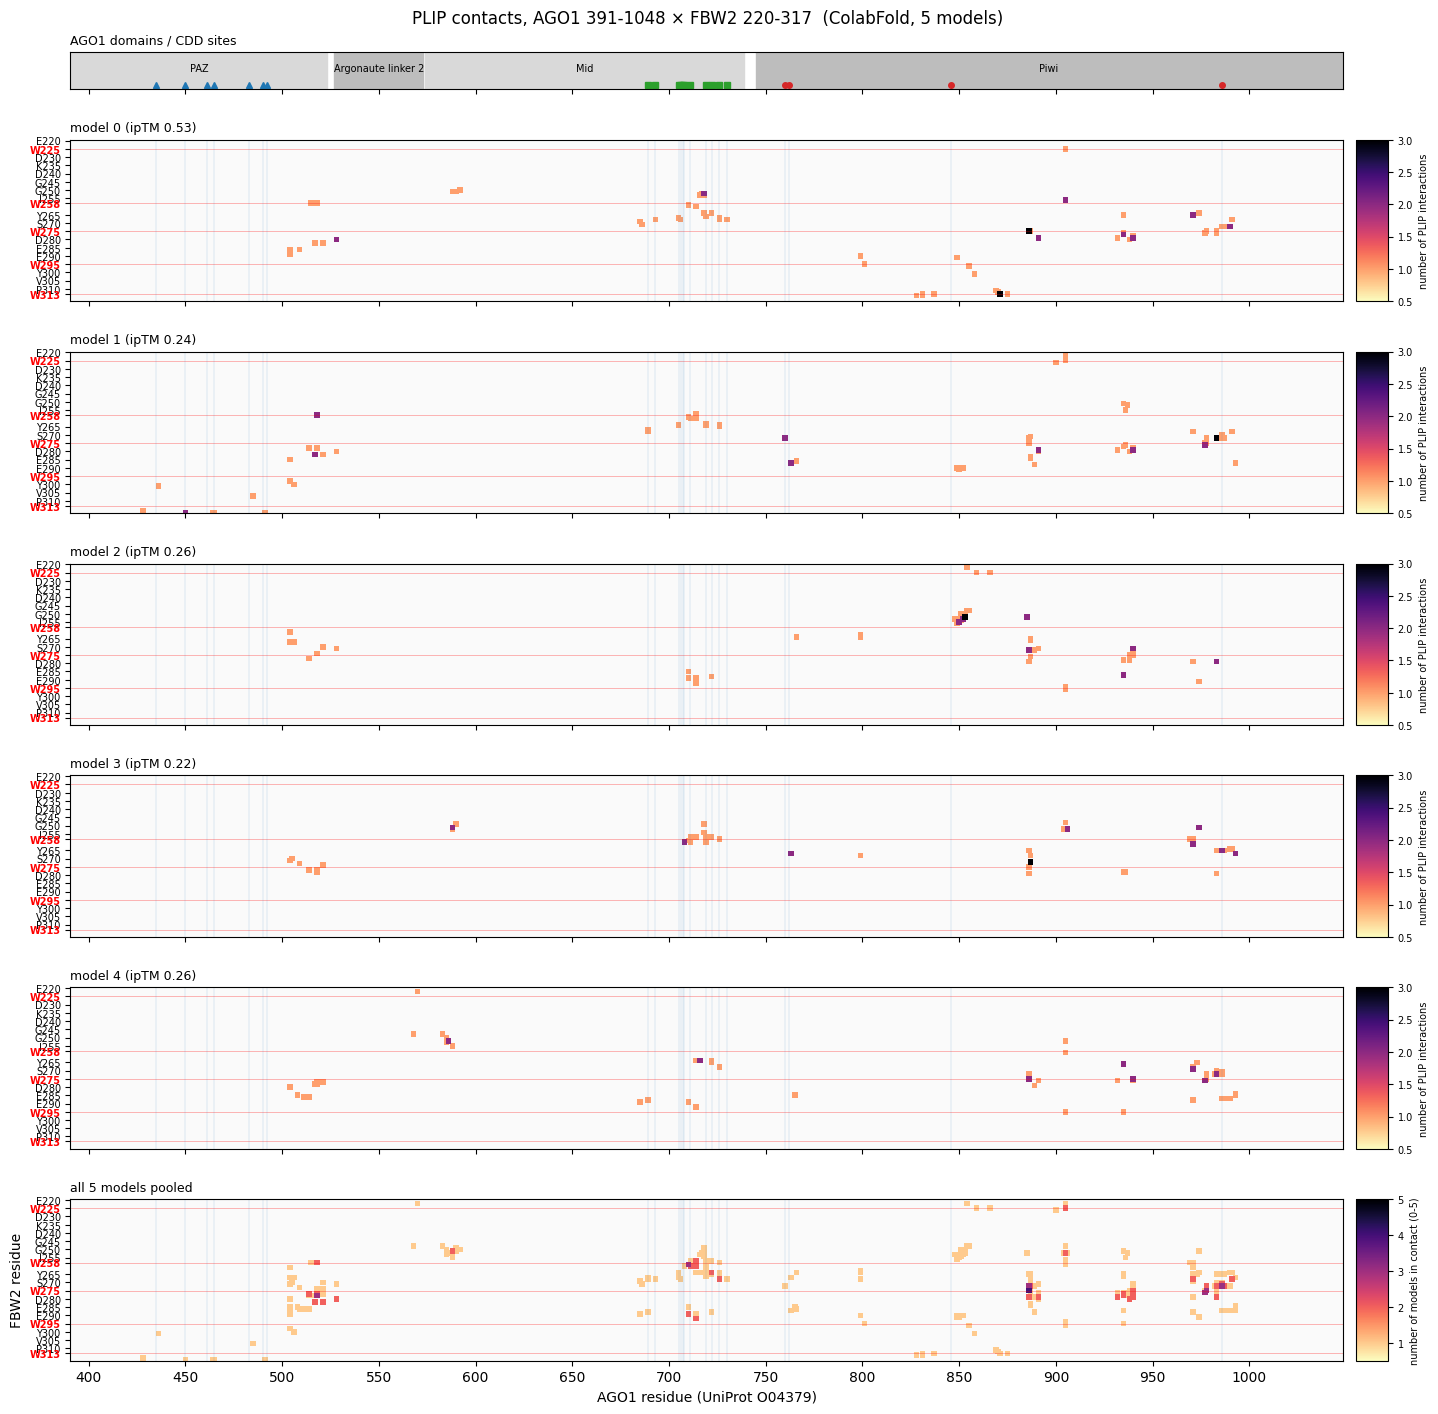

In [9]:

from matplotlib.colors import ListedColormap
from matplotlib.gridspec import GridSpec

# PAZ start / LRR end taken from the pipeline's domain annotation
paz_start = next(d["start"] for d in doms if "PAZ" in d["name"])
FBW2_START = 220      # last LRR repeat (LRR ends at 244) + the C-terminal tail
xs = np.arange(paz_start, 1049); ys = np.arange(FBW2_START, 318)
fbw2_seq = {r.seqid.num: gemmi.find_tabulated_residue(r.name).one_letter_code.upper()
            for r in gemmi.read_structure(str(PAIR_DIR / "minimized/sample_0.pdb.gz"))[0][PREY]}

pc = plip[(plip.reschain == BAIT) & (plip.reschain_lig == PREY)
          & plip.resnr.between(xs[0], xs[-1]) & plip.resnr_lig.between(ys[0], ys[-1])]
def grid(df):
    g = np.zeros((len(ys), len(xs)))
    for (y, x), n in df.groupby(["resnr_lig", "resnr"]).size().items(): g[y - ys[0], x - xs[0]] = n
    return g
per_model = {s: grid(pc[pc["sample"] == s]) for s in range(5)}
pooled = sum((g > 0).astype(int) for g in per_model.values())       # models in which the pair is in contact

fig = plt.figure(figsize=(17, 17))
gs = GridSpec(7, 2, width_ratios=[40, 1], height_ratios=[0.7] + [3] * 6, hspace=0.35, wspace=0.02)
dom_cols = ["#d9d9d9", "#bdbdbd"]
ax_top = fig.add_subplot(gs[0, 0])
for k, d in enumerate([d for d in doms if d["end"] >= xs[0]]):
    ax_top.axvspan(max(d["start"], xs[0]), d["end"], color=dom_cols[k % 2])
    ax_top.text((max(d["start"], xs[0]) + d["end"]) / 2, 0.55, d["name"].replace("Protein argonaute, ", "").replace(" domain", ""),
                ha="center", va="center", fontsize=7)
mk = {"nucleic acid": ("^", "tab:blue"), "active site": ("o", "tab:red"), "anchoring": ("s", "tab:green")}
for u, ss in site_of.items():
    for s_ in ss:
        for key, (m_, c_) in mk.items():
            if key in s_ and u >= xs[0]: ax_top.plot(u, 0.12, m_, color=c_, ms=4)
ax_top.set_xlim(xs[0] - 0.5, xs[-1] + 0.5); ax_top.set_ylim(0, 1); ax_top.set_yticks([]); ax_top.tick_params(labelbottom=False)
ax_top.set_title("AGO1 domains / CDD sites", fontsize=9, loc="left")

panels = [(f"model {s} (ipTM {conf.iptm[s]:.2f})", per_model[s], "number of PLIP interactions") for s in range(5)]
panels.append(("all 5 models pooled", pooled, "number of models in contact (0-5)"))
for r, (title, g, lab) in enumerate(panels, start=1):
    ax = fig.add_subplot(gs[r, 0], sharex=ax_top); cax = fig.add_subplot(gs[r, 1])
    vmax = 5 if title.startswith("all") else max(3, g.max())
    yy, xx = np.nonzero(g)
    cm = plt.get_cmap("magma_r")
    ax.set_facecolor("#fafafa")
    order = np.argsort(g[yy, xx])                       # strongest contacts drawn on top
    im_ = ax.scatter(xs[xx[order]], ys[yy[order]], c=g[yy, xx][order], cmap=cm, vmin=0.5, vmax=vmax,
                     marker="s", s=16, linewidths=0)
    ax.set_xlim(xs[0] - 0.5, xs[-1] + 0.5); ax.set_ylim(ys[-1] + 0.5, ys[0] - 0.5)
    trp_in = [w for w in TRP if ys[0] <= w <= ys[-1]]
    ticks = sorted({y for y in ys[::5] if all(abs(y - w) > 2 for w in trp_in)} | set(trp_in))
    ax.set_yticks(ticks); ax.set_yticklabels([f"{fbw2_seq[y]}{y}" for y in ticks], fontsize=7)
    for lbl, y in zip(ax.get_yticklabels(), ticks):
        if y in TRP: lbl.set_color("red"); lbl.set_fontweight("bold")
    for w in trp_in: ax.axhline(w, color="red", lw=0.5, alpha=0.4)
    for u in set(site_of):
        if u >= xs[0]: ax.axvline(u, color="tab:blue", lw=0.25, alpha=0.4)
    ax.set_title(title, fontsize=9, loc="left"); fig.colorbar(im_, cax=cax).set_label(lab, fontsize=7)
    cax.tick_params(labelsize=7)
    ax.tick_params(labelbottom=(r == 6))
ax.set_xticks(np.arange(400, 1049, 50)); ax.set_xlabel("AGO1 residue (UniProt O04379)"); ax.set_ylabel("FBW2 residue")
fig.suptitle(f"PLIP contacts, AGO1 {xs[0]}-{xs[-1]} × FBW2 {ys[0]}-{ys[-1]}  (ColabFold, 5 models)", y=0.905)
fig.savefig(OUT / "plip_contact_maps_paz_to_end.png", dpi=150, bbox_inches="tight")

top = (pc.assign(sample_=pc["sample"]).groupby(["resnr_lig", "resnr"])
         .agg(n_models=("sample_", "nunique"), n_int=("sample_", "size"),
              types=("interaction_type", lambda x: ",".join(sorted(set(x)))))
         .reset_index().sort_values(["n_models", "n_int"], ascending=False))
top["FBW2"] = [f"{fbw2_seq[y]}{y}" for y in top.resnr_lig]
top["AGO1"] = top.resnr
print(f"{(pooled > 0).sum()} residue pairs in contact in ≥1 model, {(pooled >= 3).sum()} in ≥3, {(pooled == 5).sum()} in all 5")
top.head(15)[["FBW2", "AGO1", "n_models", "n_int", "types"]]


**Bonus: CDD overlap.**
* The **W275 sub-pocket** is lined by the **PIWI catalytic (slicer) site**: CDD active-site residues **H986**
  (5/5 samples), **D846** (4/5) and **D760** (3/5). The indole itself is sandwiched by **K886, R940** (5/5),
  **I978** (4/5), **R887** and **S977**.
* The **W258 sub-pocket** sits between the PAZ region (T515, L518, K519, C522) and PIWI (I935, Q936, R974). In
  some samples it reaches the **MID "5′ guide anchoring site"** (Q718, N722, K726).

So the model places FBW2's acidic, Trp-rich C-terminal tail (`…NDW²⁵⁸EDCC…YLAW²⁷⁵EFFEDG…`) **in the empty guide/target
RNA channel, with W275 next to the slicer active site**. This fits FBW2 recognising AGO1 when it is *not*
loaded with a small RNA: an RNA-mimic-like occupancy of the channel. It also means AGO1 pocket mutations can change
RNA loading, which is a confounder (see the guidance on the suggested mutations below).

## 4. Suggested mutations

In [10]:
SMALL, HYDROPHOBIC, BASIC, AROMATIC = set("GAST"), set("VILMC"), set("KR"), set("FYWH")
CATALYTIC = {760, 846, 986}                    # D760, D846, H986 (slicer); CDD also lists T762

def suggest(r):
    aa = gemmi.find_tabulated_residue(r.ago1_resname).one_letter_code.upper()
    n = r.ago1_resnr; tag = f"{aa}{n}"
    if n in CATALYTIC:
        return f"{tag}A (slicer-dead control; tests whether binding needs the catalytic pocket)", "control"
    if aa in BASIC:
        return f"{tag}A / {tag}E (lose cation-π or salt bridge with the acidic FBW2 tail; E = charge reversal)", "disrupt"
    if aa in HYDROPHOBIC:
        return f"{tag}W or {tag}F (fill the Trp pocket) / {tag}A (lose packing)", "plug"
    if aa in SMALL:
        return f"{tag}W / {tag}L (fill the Trp pocket)", "plug"
    if aa in AROMATIC:
        return f"{tag}A (lose π-stacking)", "disrupt"
    return f"{tag}A", "disrupt"

top = cand[(cand.trp.isin([275, 258])) & (cand.n_samples >= 2) & (cand.n_contact >= 1)].copy()
top[["mutation", "strategy"]] = top.apply(lambda r: pd.Series(suggest(r)), axis=1)
top["caveat"] = np.where(top.cdd_site != "", "CDD site: may affect sRNA loading/slicing", "")
top["tier"] = np.select([(top.trp == 275) & (top.n_contact >= 4), (top.trp == 275)], ["A", "B"], "C")
mut = top.sort_values(["tier", "score"], ascending=[True, False])[
    ["tier", "trp", "ago1_resnr", "ago1_resname", "domain", "score", "n_samples", "n_contact", "min_dist",
     "pae", "plddt", "plip", "cdd_site", "mutation", "strategy", "caveat"]].reset_index(drop=True)
mut.to_parquet(OUT / "ago1_mutation_candidates.parquet", index=False)
mut.to_csv(OUT / "ago1_mutation_candidates.csv", index=False)   # for the bench
mut.round(2)

,tier,trp,ago1_resnr,ago1_resname,domain,score,n_samples,n_contact,min_dist,pae,plddt,plip,cdd_site,mutation,strategy,caveat
0,A,275,886,LYS,Piwi domain,1.91,5,5,2.83,10.930000,0.81,hydrogen_bonds;hydrophobic_interactions;pi-cat...,,K886A / K886E (lose cation-π or salt bridge wi...,disrupt,
1,A,275,978,ILE,Piwi domain,1.70,5,4,3.65,11.930000,0.90,hydrophobic_interactions,,I978W or I978F (fill the Trp pocket) / I978A (...,plug,
2,A,275,940,ARG,Piwi domain,1.67,5,5,3.47,11.650000,0.87,hydrogen_bonds;hydrophobic_interactions,,R940A / R940E (lose cation-π or salt bridge wi...,disrupt,
3,B,275,887,ARG,Piwi domain,1.33,5,3,3.54,11.770000,0.77,hydrophobic_interactions,,R887A / R887E (lose cation-π or salt bridge wi...,disrupt,
4,B,275,977,SER,Piwi domain,0.92,5,2,3.13,11.300000,0.87,hydrogen_bonds,,S977W / S977L (fill the Trp pocket),plug,
5,B,275,986,HIS,Piwi domain,0.85,5,1,4.04,11.640000,0.89,,Piwi_ago-like: active site,H986A (slicer-dead control; tests whether bind...,control,CDD site: may affect sRNA loading/slicing
6,B,275,932,HIS,Piwi domain,0.60,4,1,3.71,11.530000,0.87,,,H932A (lose π-stacking),disrupt,
7,B,275,941,PRO,Piwi domain,0.60,4,1,4.13,10.780000,0.92,,,P941A,disrupt,
8,B,275,942,ALA,Piwi domain,0.60,4,1,4.24,11.040000,0.94,,,A942W / A942L (fill the Trp pocket),plug,
9,B,275,938,THR,Piwi domain,0.43,2,1,2.86,12.570000,0.72,hydrogen_bonds,,T938W / T938L (fill the Trp pocket),plug,


### Recommended experimental set

**FBW2 side** (checks the model directly):

| construct | rationale |
|---|---|
| **W275A** | best-supported Trp: deep sub-pocket in 5/5 samples, lowest PAE |
| **W258A** | second channel Trp |
| **W258A/W275A** | the pair that occupies the channel |
| W225A, W295A, W313A (or all-5 W→A) | negative/contrast set: the model gives them little pocket support |
| **E279K** (± E276K, D280K) | E279 is the PLIP hub next to W275 (bonds to K886, R940, R891, H932, Y983): charge-reversal partner for the AGO1 K886E/R940E swaps |

**AGO1 side** (tier A first; check expression/loading for every mutant):
* **Tier A, W275 pocket**: **K886A/E** and **R940A/E** (basic clamp around the indole, 5/5 samples), **I978W**
  (plugs the hydrophobic floor) or I978A. **R887A/E** and **S977W** as alternatives.
* **Controls**: a slicer-dead catalytic mutant (**D760A** or **H986A**) asks whether W275 binding needs the catalytic
  pocket. The **charge-swap pair** AGO1 K886E/R940E + FBW2 E279K tests the electrostatic model specifically.
* **Tier C, W258 pocket** (PAZ/PIWI): L518W, T515W, Q936A. These sit close to the 5′ guide anchoring region, so
  they are more likely to perturb sRNA loading.

**Caveat:** every one of these AGO1 residues lines the guide/target RNA channel. FBW2 seems to prefer unloaded
AGO1, so a mutant that loads sRNA less well could *increase* FBW2 binding for reasons unrelated to the Trp pocket.
Pair each AGO1 mutant with an sRNA loading readout (sRNA co-IP), or rely on the FBW2 W→A mutants as the cleaner test.

## 5. Structure view (sample 0, the confident model)

In [11]:
import py3Dmol
pdb = gemmi.read_structure(str(PAIR_DIR / "minimized/sample_0.pdb.gz")); pdb.remove_hydrogens()
v = py3Dmol.view(width=900, height=650); v.addModel(pdb.make_pdb_string(), "pdb")
v.setStyle({"chain": BAIT}, {"cartoon": {"color": "lightgrey", "opacity": 0.85}})
v.setStyle({"chain": PREY}, {"cartoon": {"color": "#e6a817"}})
v.addStyle({"chain": PREY, "resi": TRP}, {"stick": {"colorscheme": "orangeCarbon", "radius": 0.3}})
hot = mut[mut.tier == "A"].ago1_resnr.tolist(); cat = sorted(CATALYTIC)
v.addStyle({"chain": BAIT, "resi": hot}, {"stick": {"colorscheme": "cyanCarbon"}})
v.addStyle({"chain": BAIT, "resi": cat}, {"stick": {"colorscheme": "magentaCarbon"}})
for w in [258, 275]:
    p = OUT / f"pocket_W{w}_sample0.pdb"
    if p.exists():
        v.addModel(p.read_text(), "pdb")
        v.setStyle({"model": -1}, {"sphere": {"radius": 0.3, "color": "#3b82f6" if w == 275 else "#22c55e", "opacity": 0.6}})
for w in TRP:
    v.addLabel(f"W{w}", {"fontSize": 11, "backgroundOpacity": 0.6}, {"chain": PREY, "resi": w, "atom": "CZ2"})
v.zoomTo({"chain": PREY, "resi": [258, 275]}); v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

FBW2 in amber (Trp side chains orange), tier-A AGO1 residues cyan, catalytic D760/D846/H986 magenta, W275 sub-pocket blue voxels, W258 green.

In [12]:
# ChimeraX session script: open the model + sub-pocket voxels (run `open fbw2_trp_pockets.cxc` from OUT)
lines = [f"open {os.path.relpath(PAIR_DIR / 'minimized/sample_0.pdb.gz', OUT)}",
         "hide H; cartoon; color /A lightgray; color /B goldenrod; transparency /A 40 target c",
         f"show /B:{','.join(map(str, TRP))} atoms; color /B:{','.join(map(str, TRP))} orange target a",
         f"show /A:{','.join(map(str, hot))} atoms; color /A:{','.join(map(str, hot))} cyan target a",
         f"show /A:{','.join(map(str, cat))} atoms; color /A:{','.join(map(str, cat))} magenta target a"]
for i, w in enumerate([275, 258], start=2):
    if (OUT / f"pocket_W{w}_sample0.pdb").exists():
        lines += [f"open pocket_W{w}_sample0.pdb", f"style #{i} sphere; size #{i} atomRadius 0.3; "
                  f"color #{i} {'cornflowerblue' if w == 275 else 'lightgreen'}; transparency #{i} 50"]
lines += ["label /B:" + ",".join(map(str, TRP)), "view /B:258,275"]
(OUT / "fbw2_trp_pockets.cxc").write_text("\n".join(lines) + "\n")
print(*sorted(p.name for p in OUT.iterdir()), sep="\n")

ago1_mutation_candidates.csv
ago1_mutation_candidates.parquet
fbw2_trp_pockets.cxc
kvfinder_residues.parquet
kvfinder_trp.parquet
plip_contact_maps_paz_to_end.png
pocket_W225_sample1.pdb
pocket_W225_sample2.pdb
pocket_W258_sample0.pdb
pocket_W258_sample1.pdb
pocket_W258_sample2.pdb
pocket_W258_sample3.pdb
pocket_W258_sample4.pdb
pocket_W275_sample0.pdb
pocket_W275_sample1.pdb
pocket_W275_sample2.pdb
pocket_W275_sample3.pdb
pocket_W275_sample4.pdb
pocket_W295_sample0.pdb
pocket_W295_sample1.pdb
pocket_W295_sample2.pdb
pocket_W295_sample4.pdb
pocket_W313_sample0.pdb
trp_pocket_heatmaps.png


## Limitations
* One confident sample (ipTM 0.53). The other four agree on W275 placement, but this remains a single-model
  hypothesis. A ColabFold run with more seeds, or AF3 / Boltz-2 with a guide RNA, would test whether FBW2 and the
  guide compete for the channel.
* pyKVFinder runs on apo AGO1 taken from the complex: the cavity is the *induced* pocket left by FBW2, not one
  that has to exist in free AGO1.
* Conservation was not used (the ColabFold MSAs were fetched from the server and are not stored locally). Adding a
  conservation filter would help pick AGO1 mutants that keep sRNA function.
* PLIP was run per model with the pipeline settings (`plip_contacts.parquet`). Contact lists come from minimized models.